<a href="https://colab.research.google.com/github/Ziad-Gebril/Linear-Models-and-Support-Vector-Machines/blob/soft_max/ML_assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IMPORTS**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split



# **Part A**

In [3]:
from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits,load_iris

diabetes = load_diabetes(scaled = False)
XD = diabetes.data
YD = diabetes.target

cancer = load_breast_cancer()
XC = cancer.data
YC = 1 - cancer.target    # flipping the data

digits = load_digits()
XDG = digits.data / 16  # dividing the digits data by 16
YDG = digits.target

iris = load_iris()
XI = iris.data
YI = iris.target

In [4]:
XD_tr, XD_te, yD_tr, yD_te = train_test_split(XD, YD, test_size=0.2, random_state=42)
XD_tr, XD_va, yD_tr, yD_va = train_test_split(XD_tr, yD_tr, test_size=0.25, random_state=42)

XC_tr, XC_te, yC_tr, yC_te = train_test_split(XC, YC, test_size=0.2, random_state=42, stratify=YC)
XC_tr, XC_va, yC_tr, yC_va = train_test_split(XC_tr, yC_tr, test_size=0.25, random_state=42, stratify=yC_tr)

XDG_tr, XDG_te, yDG_tr, yDG_te = train_test_split(XDG, YDG, test_size=0.2, random_state=42, stratify=YDG)
XDG_tr, XDG_va, yDG_tr, yDG_va = train_test_split(XDG_tr, yDG_tr, test_size=0.25, random_state=42, stratify=yDG_tr)

XI_tr, XI_te, yI_tr, yI_te = train_test_split(XI, YI, test_size=0.2, random_state=42, stratify=YI)
XI_tr, XI_va, yI_tr, yI_va = train_test_split(XI_tr, yI_tr, test_size=0.25, random_state=42, stratify=yI_tr)

In [5]:
for name, y_tr, y_va, y_te in [
    ("Cancer", yC_tr, yC_va, yC_te),
    ("Digits", yDG_tr, yDG_va, yDG_te),
    ("Iris", yI_tr, yI_va, yI_te)
]:
    print(f"\n{name}")
    print("Train:", np.unique(y_tr, return_counts=True))
    print("Validation:", np.unique(y_va, return_counts=True))
    print("Test:", np.unique(y_te, return_counts=True))


Cancer
Train: (array([0, 1]), array([214, 127]))
Validation: (array([0, 1]), array([71, 43]))
Test: (array([0, 1]), array([72, 42]))

Digits
Train: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Test: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

Iris
Train: (array([0, 1, 2]), array([30, 30, 30]))
Validation: (array([0, 1, 2]), array([10, 10, 10]))
Test: (array([0, 1, 2]), array([10, 10, 10]))


In [6]:
print("Diabetes:", len(yD_tr), len(yD_va), len(yD_te))
print("Cancer:", len(yC_tr), len(yC_va), len(yC_te))
print("Digits:", len(yDG_tr), len(yDG_va), len(yDG_te))
print("Iris:", len(yI_tr), len(yI_va), len(yI_te))

Diabetes: 264 89 89
Cancer: 341 114 114
Digits: 1077 360 360
Iris: 90 30 30


In [7]:
class S:
    pass

def Standardizer_fit(SS,X):
  SS.mean = np.mean(X,axis = 0)
  SS.std = np.std(X,axis = 0)


  n=len(SS.std)
  i=0
  while(i<n):
    if (SS.std[i]==0):
      SS.std[i] = 1
    i+=1

  return SS


def transform(SS, X):
      return (X - SS.mean) / SS.std   # z= (x-m)/o'


def add_bias(XX):
  one = np.ones((len(XX),1))
  X = np.column_stack((one,XX))
  return X

In [8]:
# made the test with Ai
# Diabetes
scaler_D = S()
Standardizer_fit(scaler_D, XD_tr)

XD_tr = transform(scaler_D, XD_tr)
XD_va = transform(scaler_D, XD_va)
XD_te = transform(scaler_D, XD_te)


# Cancer
scaler_C = S()
Standardizer_fit(scaler_C, XC_tr)

XC_tr = transform(scaler_C, XC_tr)
XC_va = transform(scaler_C, XC_va)
XC_te = transform(scaler_C, XC_te)


# Iris
scaler_I = S()
Standardizer_fit(scaler_I, XI_tr)

XI_tr = transform(scaler_I, XI_tr)
XI_va = transform(scaler_I, XI_va)
XI_te = transform(scaler_I, XI_te)


for name, X_tr, X_va, X_te in [
    ("Diabetes", XD_tr, XD_va, XD_te),
    ("Cancer", XC_tr, XC_va, XC_te),
    ("Iris", XI_tr, XI_va, XI_te)
]:
    print(f"\n{name}")
    print("Train mean:", np.round(X_tr.mean(axis=0), 6))
    print("Train std:", np.round(X_tr.std(axis=0), 6))


Diabetes
Train mean: [-0.  0. -0. -0. -0. -0.  0. -0.  0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Cancer
Train mean: [ 0.  0. -0.  0. -0. -0.  0. -0.  0. -0.  0.  0. -0. -0. -0.  0. -0. -0.
  0. -0. -0.  0. -0. -0. -0.  0.  0. -0.  0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

Iris
Train mean: [-0.  0. -0.  0.]
Train std: [1. 1. 1. 1.]


In [9]:
def mse(y_t, y_p):
  errors = y_t - y_p
  return np.mean(np.array(errors) ** 2)


def rmse(y_t, y_p):
  return np.sqrt(mse(y_t, y_p))


def r2(y_t, y_p):
  s1= np.sum((y_t-y_p)**2) # comparing each one to the predicted one
  s2 = np.sum(( np.mean(y_t)-y_t)**2) # comparing each one to the mean of all of them
  return 1-(s1/s2)


def accuracy(y_t, pred):
  T= np.sum(y_t == pred)
  total = len(y_t)
  return T/total

#def conf_matrix(y, pred):
 # classesT =np.unique(y)
  #CM = np.zeros((K,K))
##
 # classesP =np.unique(y)
 #
  #i=0
#
 # while(i<K):
  #  TR = np.where(classesT == y[i])[0][0]
   # PR = np.where(classesP == pred[i])[0][0]
    #CM[TR][PR] += 1
#
 #   i+=1
#
 # return CM\\

def confusion_matrix(y, pred, K):
    CM = np.bincount(
        K * y + pred,
        minlength=K * K
    ).reshape(K, K)

    return CM

In [10]:
def precision(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  PR = np.zeros(n)

  while(i<n):
    if np.sum(CM[:, i]) == 0:
      PR[i] = 0
      # Precision = 0 for a class that is never predicted
    else:
      PR[i] = d[i]/np.sum(CM[:, i]) # to take only one column
    i+=1
  return PR

def recall(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  RC = np.zeros(n)

  while(i<n):
    if np.sum(CM[i, :]) == 0:
      RC[i] = 0
      # recall = 0 for a class that is never Existed
    else:
      RC[i] = d[i]/np.sum(CM[i, :]) # to take only one row
    i+=1
  return RC


def F1(CM):
  P = precision(CM)
  R = recall(CM)

  n=len(P)
  i=0
  F = np.zeros(n)

  while(i<n):
    NOM = P[i]*R[i]
    DNOM = P[i]+R[i]
    if DNOM == 0:
      F[i] = 0
    else:
      F[i]= 2*NOM/DNOM
    i+=1
  return F

In [11]:
y_t = np.array([0, 1, 2, 0, 1])
y_p = np.array([0, 1, 0, 2, 1])

classes =np.unique(y_t)
n = len(classes)

CM = confusion_matrix(y_t, y_p, n)

macro_precision = np.mean(precision(CM))
macro_recall = np.mean(recall(CM))
macro_F1 = np.mean(F1(CM))


print("Precision:", precision(CM))
print("Macro Precision:", macro_precision)

print("Recall:", recall(CM))
print("Macro Recall:", macro_recall)

print("F1:", F1(CM))
print("Macro F1:", macro_F1)

Precision: [0.5 1.  0. ]
Macro Precision: 0.5
Recall: [0.5 1.  0. ]
Macro Recall: 0.5
F1: [0.5 1.  0. ]
Macro F1: 0.5


In [12]:
print(CM)
print(precision(CM))
print(F1(CM))

[[1 0 1]
 [0 2 0]
 [1 0 0]]
[0.5 1.  0. ]
[0.5 1.  0. ]


In [13]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_fscore_support
)

rng = np.random.default_rng(42)

N = 500
K = 4

# Regression
y_reg = rng.normal(size=N)
pred_reg = rng.normal(size=N)

# Classification
y = rng.integers(0, K, size=N)
pred = rng.integers(0, K, size=N)

In [14]:
np.testing.assert_allclose(
    mse(y_reg, pred_reg),
    mean_squared_error(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    rmse(y_reg, pred_reg),
    np.sqrt(mean_squared_error(y_reg, pred_reg)),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    r2(y_reg, pred_reg),
    r2_score(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

print("Regression metrics: PASSED")

Regression metrics: PASSED


In [15]:
CM = confusion_matrix(y, pred, K)

CM_ref = sk_confusion_matrix(
    y, pred,
    labels=np.arange(K)
)

np.testing.assert_array_equal(CM, CM_ref)

print("Confusion matrix: PASSED")

Confusion matrix: PASSED


In [16]:
P_ref, R_ref, F_ref, _ = precision_recall_fscore_support(
    y, pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)

np.testing.assert_allclose(
    accuracy(y, pred),
    accuracy_score(y, pred),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    precision(CM), P_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    recall(CM), R_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    F1(CM), F_ref,
    atol=1e-12, rtol=0
)

print("Classification metrics: PASSED")

Classification metrics: PASSED


In [17]:
np.testing.assert_allclose(
    np.mean(precision(CM)),
    np.mean(P_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(recall(CM)),
    np.mean(R_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(F1(CM)),
    np.mean(F_ref),
    atol=1e-12, rtol=0
)

print("Macro averages: PASSED")

Macro averages: PASSED


In [18]:
def grad_check(f, grad, w, eps=1e-5):
    w = np.array(w, dtype=float)

    g_analytic = grad(w).flatten()
    g_numeric = np.zeros(w.size)

    # Select entries to check
    rng = np.random.default_rng(42)

    if w.size > 100:
        indices = rng.choice(w.size, size=100, replace=False)
    else:
        indices = np.arange(w.size)

    # Central differences
    for i in indices:
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps

        g_numeric[i] = (f(w_plus) - f(w_minus)) / (2 * eps)

    # Compare only the selected entries
    g_a = g_analytic[indices]
    g_n = g_numeric[indices]

    numerator = np.linalg.norm(g_a - g_n)
    denominator = max(
        np.linalg.norm(g_a),
        np.linalg.norm(g_n),
        1e-12
    )

    return numerator / denominator

In [19]:
# a test fro grad from the AI

def test_f(w):
    return np.sum(w**2)

def test_grad(w):
    return 2*w

rng = np.random.default_rng(42)
w = rng.normal(0, 0.1, size=5)

error = grad_check(test_f, test_grad, w)

print("Relative error:", error)
print("Passed:", error < 1e-6)

Relative error: 1.1752888136783617e-12
Passed: True



# **PART D**



In [20]:
def softmax(S):
    S_shifted = S - np.max(S, axis=1, keepdims=True)
    exp_scores = np.exp(S_shifted)
    return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)


def cross_entropy_loss(W, X, y, lam):
    N = len(y)
    K = W.shape[1]

    scores = X @ W

    max_scores = np.max(scores, axis=1, keepdims=True)
    log_sum_exp = max_scores[:, 0] + np.log(np.sum(np.exp(scores - max_scores), axis=1))
    correct_scores = scores[np.arange(N), y]
    loss = np.mean(log_sum_exp - correct_scores)

    loss += (lam / 2) * np.sum(W[1:, :] ** 2)

    return loss


def softmax_gradient(W, X, y, lam):
    N = len(y)
    K = W.shape[1]

    scores = X @ W
    P = softmax(scores)

    Y = np.zeros((N, K))
    Y[np.arange(N), y] = 1

    grad = (X.T @ (P - Y)) / N
    grad[1:, :] += lam * W[1:, :]

    return grad



K = 10
W_zero = np.zeros((XDG_tr.shape[1] + 1, K))
XDG_tr_bias = add_bias(XDG_tr)

loss_zero = cross_entropy_loss(W_zero, XDG_tr_bias, yDG_tr, 0.1)

print("Loss when W = 0:", loss_zero)
print("ln(10):", np.log(10))
print("They are equal:", np.isclose(loss_zero, np.log(10)))



gradient_error = grad_check(lambda W: cross_entropy_loss(W, XDG_tr_bias, yDG_tr, 0.1),lambda W: softmax_gradient(W, XDG_tr_bias, yDG_tr, 0.1),np.random.default_rng(42).normal(0, 0.01, size=W_zero.shape))

print("Gradient relative error:", gradient_error)
print("Gradient check passed:", gradient_error < 1e-6)

Loss when W = 0: 2.3025850929940463
ln(10): 2.302585092994046
They are equal: True
Gradient relative error: 1.0638113274820434e-09
Gradient check passed: True


\
\begin{aligned}
\text{softmax}(s+c\mathbf{1})_i
&= \frac{e^{s_i+c}}{\sum_j e^{s_j+c}} \\[6pt]
&= \frac{e^c e^{s_i}}{e^c \sum_j e^{s_j}} \\[6pt]
&= \frac{e^{s_i}}{\sum_j e^{s_j}} \\[6pt]
&= \text{softmax}(s)_i
\end{aligned}

Used Ai for the syntax of writing

In [21]:
s = np.array([1000, 1001, 1002])

s_shifted = s - np.max(s)
exp_scores = np.exp(s_shifted)
probabilities = exp_scores / np.sum(exp_scores)

print("Original scores:", s)
print("Shifted scores:", s_shifted)
print("Softmax probabilities:", probabilities)

print("Sum:", np.sum(probabilities))

Original scores: [1000 1001 1002]
Shifted scores: [-2 -1  0]
Softmax probabilities: [0.09003057 0.24472847 0.66524096]
Sum: 0.9999999999999999


    Eta  Final training loss  Final validation loss  Final training accuracy  \
0  0.01             0.808641               0.837388                 0.924791   
1  0.10             0.203817               0.238951                 0.960074   
2  0.50             0.086785               0.138329                 0.988858   
3  1.00             0.056569               0.119327                 0.996286   

   Final validation accuracy  
0                   0.911111  
1                   0.950000  
2                   0.961111  
3                   0.961111  


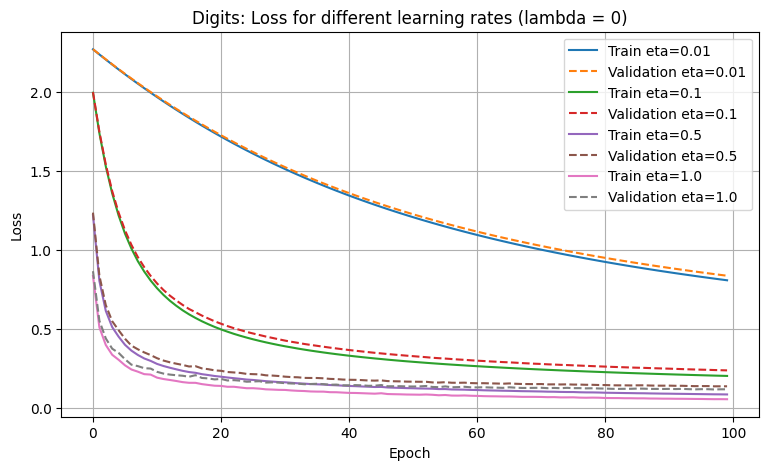

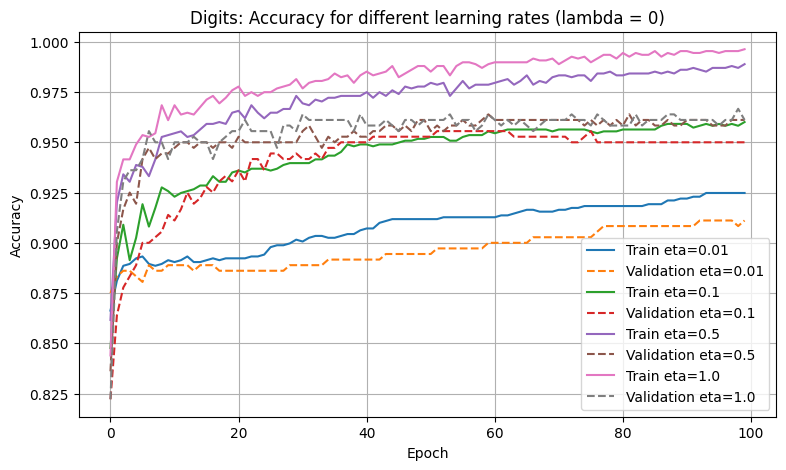

Selected eta: 1.0


In [26]:
def train_softmax(X_tr, y_tr, X_va, y_va, lam, eta, epochs=100, batch_size=64):
    N = len(y_tr)
    K = len(np.unique(y_tr))

    W = np.zeros((X_tr.shape[1], K))

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    rng = np.random.default_rng(42)

    for epoch in range(epochs):
        order = rng.permutation(N)
        X_shuffled = X_tr[order]
        y_shuffled = y_tr[order]

        for start in range(0, N, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            grad = softmax_gradient(W, X_batch, y_batch, lam)
            W = W - eta * grad

        train_losses.append(cross_entropy_loss(W, X_tr, y_tr, lam))
        val_losses.append(cross_entropy_loss(W, X_va, y_va, lam))

        train_pred = np.argmax(softmax(X_tr @ W), axis=1)
        val_pred = np.argmax(softmax(X_va @ W), axis=1)

        train_accuracies.append(accuracy(y_tr, train_pred))
        val_accuracies.append(accuracy(y_va, val_pred))

    history = {"train_loss": train_losses,"val_loss": val_losses,"train_accuracy": train_accuracies,"val_accuracy": val_accuracies}

    return W, history



XDG_tr_b = add_bias(XDG_tr)
XDG_va_b = add_bias(XDG_va)
XDG_te_b = add_bias(XDG_te)


eta_values = [0.01, 0.1, 0.5, 1.0]
eta_results = []
eta_models = {}
eta_histories = {}

for current_eta in eta_values:
    W_current, history = train_softmax(
        XDG_tr_b, yDG_tr,
        XDG_va_b, yDG_va,
        lam=0, eta=current_eta, epochs=100, batch_size=64
    )

    eta_models[current_eta] = W_current
    eta_histories[current_eta] = history

    eta_results.append([ current_eta, history["train_loss"][-1],history["val_loss"][-1], history["train_accuracy"][-1],history["val_accuracy"][-1]])

eta_df = pd.DataFrame(eta_results,columns=["Eta", "Final training loss", "Final validation loss","Final training accuracy", "Final validation accuracy"])

print(eta_df)


plt.figure(figsize=(9, 5))
for current_eta in eta_values:
    plt.plot(eta_histories[current_eta]["train_loss"],label="Train eta=" + str(current_eta))

    plt.plot( eta_histories[current_eta]["val_loss"],linestyle="--", label="Validation eta=" + str(current_eta))

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Digits: Loss for different learning rates (lambda = 0)")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(9, 5))
for current_eta in eta_values:

    plt.plot(eta_histories[current_eta]["train_accuracy"],label="Train eta=" + str(current_eta))

    plt.plot(eta_histories[current_eta]["val_accuracy"], linestyle="--",label="Validation eta=" + str(current_eta))

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Digits: Accuracy for different learning rates (lambda = 0)")
plt.legend()
plt.grid()
plt.show()


best_eta_row = eta_df.loc[eta_df["Final validation loss"].idxmin()]
best_eta = best_eta_row["Eta"]

print("Selected eta:", best_eta)

In [27]:
lambda_values = [0, 1e-4, 1e-3, 1e-2, 1e-1]

results = []
trained_models = {}

for lam in lambda_values:
    W_current, history = train_softmax(XDG_tr_b, yDG_tr,XDG_va_b, yDG_va,lam=lam, eta=best_eta, epochs=100, batch_size=64)

    val_accuracy = history["val_accuracy"][-1]
    val_loss = history["val_loss"][-1]

    results.append([lam, val_loss, val_accuracy])
    trained_models[lam] = W_current

results = pd.DataFrame(results,columns=["Lambda", "Final validation loss", "Final validation accuracy"])

print(results)


best_row = results.sort_values(["Final validation accuracy", "Lambda"],ascending=[False, False]).iloc[0]

best_lambda = best_row["Lambda"]
best_W = trained_models[best_lambda]

test_pred = np.argmax(softmax(XDG_te_b @ best_W), axis=1)
test_accuracy = accuracy(yDG_te, test_pred)

print("Selected lambda:", best_lambda)
print("Test accuracy:", test_accuracy)

   Lambda  Final validation loss  Final validation accuracy
0  0.0000               0.119327                   0.961111
1  0.0001               0.150828                   0.963889
2  0.0010               0.304194                   0.966667
3  0.0100               0.785556                   0.927778
4  0.1000               1.803547                   0.633333
Selected lambda: 0.001
Test accuracy: 0.9527777777777777


In [29]:
from sklearn.linear_model import LogisticRegression

lambda_grid = [1e-4, 1e-3, 1e-2, 1e-1]
comparison_results = []

N_train = len(yDG_tr)

for lam in lambda_grid:

    W_own, history = train_softmax(XDG_tr_b, yDG_tr,XDG_va_b, yDG_va,lam=lam, eta=best_eta, epochs=100, batch_size=64)

    own_val_pred = np.argmax(softmax(XDG_va_b @ W_own), axis=1)
    own_test_pred = np.argmax(softmax(XDG_te_b @ W_own), axis=1)


    C_value = 1 / (lam * N_train)

    sklearn_model = LogisticRegression(C=C_value,max_iter=10000,solver="lbfgs")
    sklearn_model.fit(XDG_tr, yDG_tr)

    sklearn_val_pred = sklearn_model.predict(XDG_va)
    sklearn_test_pred = sklearn_model.predict(XDG_te)

    comparison_results.append([lam,accuracy(yDG_va, own_val_pred),accuracy(yDG_va, sklearn_val_pred),accuracy(yDG_te, own_test_pred),accuracy(yDG_te, sklearn_test_pred),accuracy(sklearn_test_pred, own_test_pred)])

comparison_df = pd.DataFrame(comparison_results,columns=["Lambda", "Own validation accuracy", "Sklearn validation accuracy","Own test accuracy", "Sklearn test accuracy", "Test prediction agreement"])

print("Comparison using C = 1 / (lambda * N_train):")
print(comparison_df)


C_values = [0.1, 1, 10, 100]
C_results = []

for C_value in C_values:
    model = LogisticRegression(C=C_value, max_iter=10000,solver="lbfgs")
    model.fit(XDG_tr, yDG_tr)

    val_pred = model.predict(XDG_va)
    test_pred = model.predict(XDG_te)

    C_results.append([C_value,accuracy(yDG_va, val_pred),accuracy(yDG_te, test_pred)])

C_df = pd.DataFrame(C_results,columns=["C", "Validation accuracy", "Test accuracy"])

print("\nScikit-learn results for the required C sweep:")
print(C_df)

Comparison using C = 1 / (lambda * N_train):
   Lambda  Own validation accuracy  Sklearn validation accuracy  \
0  0.0001                 0.963889                     0.975000   
1  0.0010                 0.966667                     0.972222   
2  0.0100                 0.927778                     0.947222   
3  0.1000                 0.633333                     0.902778   

   Own test accuracy  Sklearn test accuracy  Test prediction agreement  
0           0.958333               0.961111                   0.983333  
1           0.952778               0.955556                   0.991667  
2           0.925000               0.933333                   0.977778  
3           0.619444               0.886111                   0.655556  

Scikit-learn results for the required C sweep:
       C  Validation accuracy  Test accuracy
0    0.1             0.950000       0.938889
1    1.0             0.972222       0.955556
2   10.0             0.963889       0.955556
3  100.0             0.961

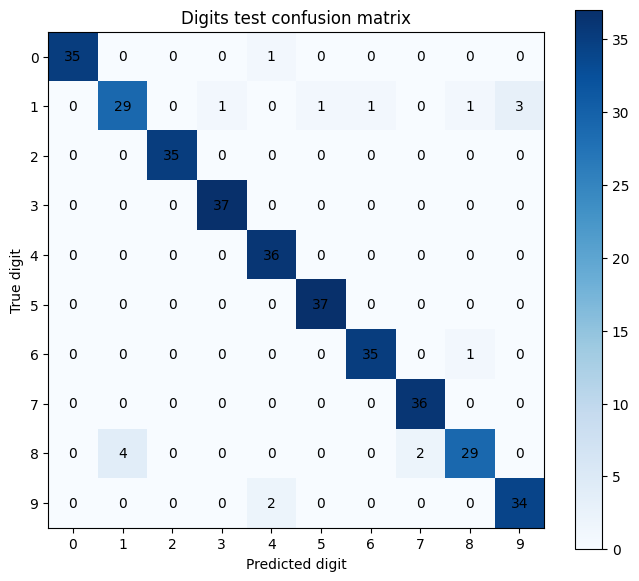

   Digit  Precision  Recall      F1
0      0     1.0000  0.9722  0.9859
1      1     0.8788  0.8056  0.8406
2      2     1.0000  1.0000  1.0000
3      3     0.9737  1.0000  0.9867
4      4     0.9231  1.0000  0.9600
5      5     0.9737  1.0000  0.9867
6      6     0.9722  0.9722  0.9722
7      7     0.9474  1.0000  0.9730
8      8     0.9355  0.8286  0.8788
9      9     0.9189  0.9444  0.9315
Three most confused digit pairs:
True: 8 / Predicted: 1 / Count: 4
True: 1 / Predicted: 9 / Count: 3
True: 9 / Predicted: 4 / Count: 2


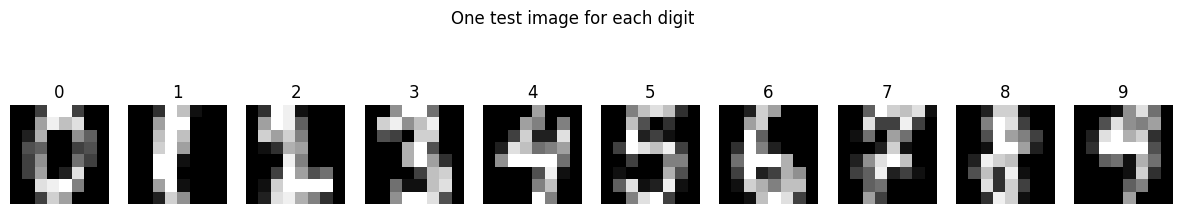

In [30]:
#used Ai for the image
test_pred = np.argmax(softmax(XDG_te_b @ best_W), axis=1)

CM_digits = confusion_matrix(yDG_te, test_pred, 10)

plt.figure(figsize=(8, 7))
plt.imshow(CM_digits, cmap="Blues")
plt.colorbar()
plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.title("Digits test confusion matrix")
plt.xticks(np.arange(10))
plt.yticks(np.arange(10))

for i in range(10):
    for j in range(10):
        plt.text(j, i, CM_digits[i, j], ha="center", va="center")

plt.show()

class_precision = precision(CM_digits)
class_recall = recall(CM_digits)
class_f1 = F1(CM_digits)

metrics_df = pd.DataFrame({"Digit": np.arange(10),"Precision": class_precision, "Recall": class_recall,"F1": class_f1})

print(metrics_df.round(4))

confusions = []

for true_digit in range(10):
    for predicted_digit in range(10):
        if true_digit != predicted_digit:
            confusions.append([CM_digits[true_digit, predicted_digit],true_digit,predicted_digit])

confusions.sort(reverse=True)

print("Three most confused digit pairs:")
for count, true_digit, predicted_digit in confusions[:3]:
    print("True:", true_digit,"/ Predicted:", predicted_digit,"/ Count:", count)

plt.figure(figsize=(15, 3))

for digit in range(10):
    index = np.where(yDG_te == digit)[0][0]

    plt.subplot(1, 10, digit + 1)
    plt.imshow(XDG_te[index].reshape(8, 8), cmap="gray")
    plt.title(str(digit))
    plt.axis("off")

plt.suptitle("One test image for each digit")
plt.show()


The hardest digits are the ones with the largest off-diagonal counts in the confusion matrix. A linear model can confuse digits when their pixel patterns are similar. Since the model uses raw pixels, it cannot easily learn more complex shapes or different writing styles. Some digits may also look different depending on how they are written or positioned.

### Two-Class Softmax Equivalence to Logistic Regression

For two classes, let the score columns be:

\[
s_0 = x^T w_0
\]

\[
s_1 = x^T w_1
\]

Then:

\[
\begin{aligned}
P(y=1\mid x)
&= \frac{e^{s_1}}{e^{s_0}+e^{s_1}} \\[8pt]
&= \frac{1}{1+e^{-(s_1-s_0)}} \\[8pt]
&= \frac{1}{1+e^{-x^T(w_1-w_0)}} \\[8pt]
&= \sigma\left(x^T(w_1-w_0)\right)
\end{aligned}
\]

This is the logistic sigmoid formula, so a two-class softmax classifier is equivalent to logistic regression.

In [31]:

X_cancer_test_b = add_bias(XC_te)

rng = np.random.default_rng(42)


W_two = rng.normal(0, 0.1, size=(31, 2))


scores_two = X_cancer_test_b @ W_two
P_two = softmax(scores_two)
softmax_probability = P_two[:, 1]


z = X_cancer_test_b @ (W_two[:, 1] - W_two[:, 0])
sigmoid_probability = 1 / (1 + np.exp(-z))

difference = np.max(np.abs(softmax_probability - sigmoid_probability))

print("Maximum probability difference:", difference)
print("Verification passed:", difference < 1e-12)

Maximum probability difference: 1.1102230246251565e-16
Verification passed: True


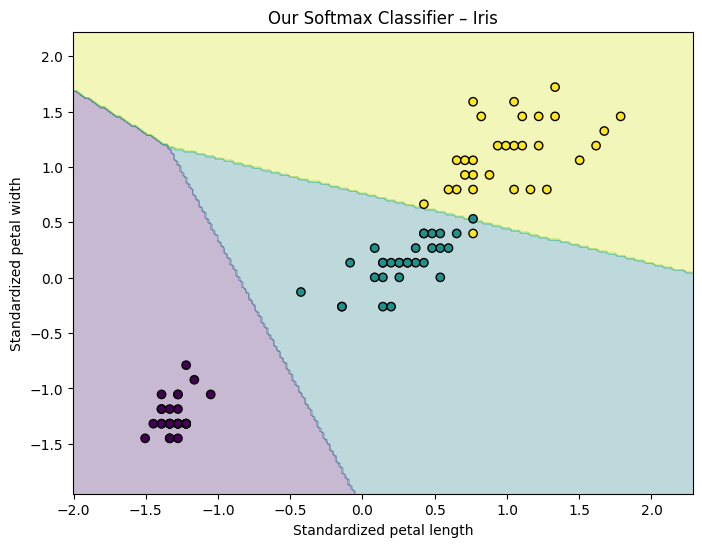

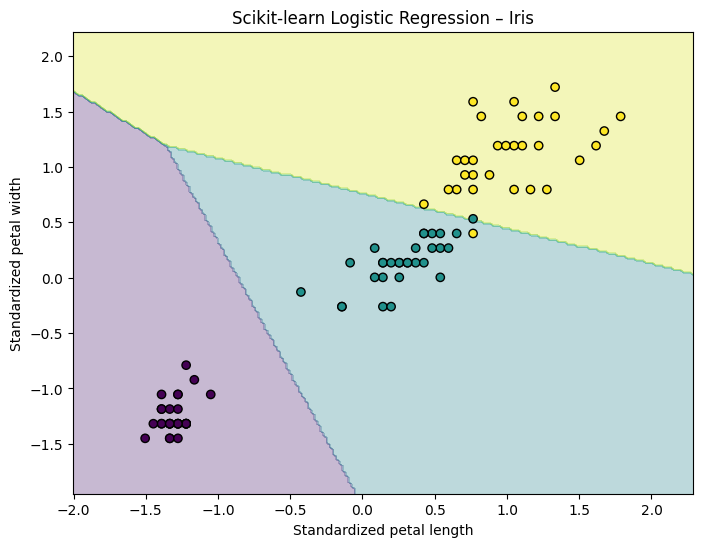

In [32]:

XI_tr_petal = XI_tr[:, 2:4]
XI_te_petal = XI_te[:, 2:4]

XI_tr_petal_b = add_bias(XI_tr_petal)


def train_softmax_full_batch(X, y, lam, eta, epochs):
    K = len(np.unique(y))
    W = np.zeros((X.shape[1], K))

    for epoch in range(epochs):
        grad = softmax_gradient(W, X, y, lam)
        W = W - eta * grad

    return W


iris_lambda = best_lambda

W_iris = train_softmax_full_batch(XI_tr_petal_b,yI_tr,lam=iris_lambda,eta=0.5,epochs=2000)


C_iris = 1 / (iris_lambda * len(yI_tr))

iris_sklearn = LogisticRegression(C=C_iris,max_iter=10000,solver="lbfgs")
iris_sklearn.fit(XI_tr_petal, yI_tr)


x_min = XI_tr_petal[:, 0].min() - 0.5
x_max = XI_tr_petal[:, 0].max() + 0.5
y_min = XI_tr_petal[:, 1].min() - 0.5
y_max = XI_tr_petal[:, 1].max() + 0.5

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),np.linspace(y_min, y_max, 200))

grid = np.column_stack((xx.ravel(), yy.ravel()))
grid_b = add_bias(grid)


own_grid_pred = np.argmax(softmax(grid_b @ W_iris), axis=1)
own_grid_pred = own_grid_pred.reshape(xx.shape)


sk_grid_pred = iris_sklearn.predict(grid)
sk_grid_pred = sk_grid_pred.reshape(xx.shape)


plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, own_grid_pred, alpha=0.3, cmap="viridis")
plt.scatter(XI_tr_petal[:, 0], XI_tr_petal[:, 1],c=yI_tr, edgecolors="black", cmap="viridis")
plt.xlabel("Standardized petal length")
plt.ylabel("Standardized petal width")
plt.title("Our Softmax Classifier – Iris")
plt.show()


plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, sk_grid_pred, alpha=0.3, cmap="viridis")
plt.scatter(XI_tr_petal[:, 0], XI_tr_petal[:, 1],c=yI_tr, edgecolors="black", cmap="viridis")
plt.xlabel("Standardized petal length")
plt.ylabel("Standardized petal width")
plt.title("Scikit-learn Logistic Regression – Iris")
plt.show()